# Proyecto final · Olist: del pedido a la reseña

**Equipo:** Molina Campos Noel Amílcar
Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Los datos están en el esquema `final`.

In [1]:
import warnings
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool
from sqlalchemy.engine import URL 

warnings.filterwarnings("ignore")
#motor = create_engine(getpass("Cadena de conexión: "), poolclass=NullPool)

DB_HOST = "aws-0-us-west-2.pooler.supabase.com"
DB_PORT = 6543
DB_NAME = "postgres"
DB_USER = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
DB_PASSWORD = getpass("Contraseña de solo lectura: ")

url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
                  # el bloque, igual que en la semana 5

motor = create_engine(url, poolclass=NullPool)    # en vez de la línea de getpass

pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [2]:
# TU CÓDIGO AQUÍ  postgresql+psycopg2://USUARIO: kodigo CONTRASEÑA@HOST:PUERTO/BASE
nombre_tabla = "orders"

# Las primeras filas
pd.read_sql(f"SELECT * FROM final.{nombre_tabla} LIMIT 5", motor)

# Cuántas filas tiene
pd.read_sql(f"SELECT COUNT(*) AS total_filas FROM final.{nombre_tabla}", motor)

,total_filas
0,80450


total_pedidos = pd.read_sql("SELECT COUNT(*) AS total FROM final.orders", motor)

pedidos_entregados = pd.read_sql(
    "SELECT COUNT(*) AS total FROM final.orders WHERE order_status = '...'", motor
)

pedidos_con_fecha_de_entrega = pd.read_sql(
    "SELECT COUNT(*) AS total FROM final.orders "
    "WHERE order_status = '...' AND ... IS NOT NULL", motor
)

pedidos_con_resena = pd.read_sql(
    "SELECT COUNT(*) AS total FROM final.orders "
    "WHERE order_status = '...' AND ... IS NOT NULL "
    "AND order_id IN (SELECT order_id FROM final.order_reviews)", motor
)

In [3]:
consulta_contrato = """
WITH articulos_por_pedido AS (
    SELECT
        articulo.order_id,
        COUNT(*)                           AS n_items,
        COUNT(DISTINCT articulo.seller_id) AS n_vendedores,
        SUM(articulo.price)                AS precio_total,
        SUM(articulo.freight_value)        AS flete_total,
        SUM(producto.product_weight_g)     AS peso_total_g,
        AVG(producto.product_photos_qty)   AS fotos_promedio
    FROM final.order_items AS articulo
    LEFT JOIN final.products AS producto ON producto.product_id = articulo.product_id
    GROUP BY articulo.order_id
),
primer_articulo AS (
    SELECT
        articulo.order_id,
        producto.product_category_name AS categoria,
        vendedor.seller_state          AS estado_vendedor
    FROM final.order_items AS articulo
    LEFT JOIN final.products AS producto ON producto.product_id = articulo.product_id
    LEFT JOIN final.sellers  AS vendedor ON vendedor.seller_id  = articulo.seller_id
    WHERE articulo.order_item_id = 1
),
pago_principal AS (
    SELECT DISTINCT ON (order_id) order_id, payment_type AS tipo_pago
    FROM final.order_payments
    ORDER BY order_id, payment_value DESC, payment_sequential
),
cuotas_por_pedido AS (
    SELECT order_id, MAX(payment_installments) AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
),
resena_mas_reciente AS (
    SELECT DISTINCT ON (order_id)
        order_id,
        CASE WHEN review_score IN (1, 2) THEN 1 ELSE 0 END AS mala_resena
    FROM final.order_reviews
    ORDER BY order_id, review_answer_timestamp DESC NULLS LAST
)
SELECT
    pedido.order_id,
    pedido.order_purchase_timestamp,
    pedido.order_approved_at,
    pedido.order_delivered_carrier_date,
    pedido.order_delivered_customer_date,
    pedido.order_estimated_delivery_date,
    cliente.customer_state AS estado_cliente,
    resumen_articulos.n_items,
    resumen_articulos.n_vendedores,
    resumen_articulos.precio_total,
    resumen_articulos.flete_total,
    resumen_articulos.peso_total_g,
    resumen_articulos.fotos_promedio,
    articulo_uno.categoria,
    articulo_uno.estado_vendedor,
    pago.tipo_pago,
    cuotas.cuotas_max,
    resena.mala_resena
FROM final.orders AS pedido
JOIN final.customers AS cliente          ON cliente.customer_id = pedido.customer_id
JOIN resena_mas_reciente AS resena       ON resena.order_id = pedido.order_id
LEFT JOIN articulos_por_pedido AS resumen_articulos ON resumen_articulos.order_id = pedido.order_id
LEFT JOIN primer_articulo AS articulo_uno           ON articulo_uno.order_id = pedido.order_id
LEFT JOIN pago_principal AS pago                    ON pago.order_id = pedido.order_id
LEFT JOIN cuotas_por_pedido AS cuotas               ON cuotas.order_id = pedido.order_id
WHERE pedido.order_status = 'delivered'
  AND pedido.order_delivered_customer_date IS NOT NULL
ORDER BY pedido.order_id
"""

pedidos = pd.read_sql(consulta_contrato, motor)

In [4]:
from pathlib import Path

archivo_cache = Path("pedidos_cache.parquet")

if archivo_cache.exists():
    pedidos = pd.read_parquet("pedidos_cache.parquet")
else:
    pedidos = pd.read_sql(consulta_contrato, motor)
    pedidos.to_parquet(archivo_cache, index=False)

Esta celda verifica el contrato. Debe imprimir `True`:

In [5]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


In [60]:
pedidos.info()

<class 'pandas.DataFrame'>
RangeIndex: 77304 entries, 0 to 77303
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       77304 non-null  str           
 1   order_purchase_timestamp       77304 non-null  datetime64[us]
 2   order_approved_at              77290 non-null  datetime64[us]
 3   order_delivered_carrier_date   77303 non-null  datetime64[us]
 4   order_delivered_customer_date  77304 non-null  datetime64[us]
 5   order_estimated_delivery_date  77304 non-null  datetime64[us]
 6   estado_cliente                 77304 non-null  str           
 7   n_items                        77304 non-null  int64         
 8   n_vendedores                   77304 non-null  int64         
 9   precio_total                   77304 non-null  float64       
 10  flete_total                    77304 non-null  float64       
 11  peso_total_g              

In [6]:
pedidos.head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,1,1,58.9,13.29,650.0,4.0,cool_stuff,SP,credit_card,2.0,0
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,1,1,239.9,19.93,30000.0,2.0,pet_shop,SP,credit_card,3.0,0
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,MG,1,1,199.0,17.87,3050.0,2.0,moveis_decoracao,MG,credit_card,5.0,0
3,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,SP,1,1,199.9,18.14,3750.0,1.0,ferramentas_jardim,PR,credit_card,3.0,0
4,00048cc3ae777c65dbb7d2a0634bc1ea,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-17 11:05:55,2017-05-22 13:44:35,2017-06-06,MG,1,1,21.9,12.69,450.0,1.0,utilidades_domesticas,SP,boleto,1.0,0


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

In [7]:
# FALTANTES
faltantes_por_columna = pedidos.isna().sum()
porcentaje_de_faltantes = (faltantes_por_columna / len(pedidos) * 100).round(2)

resumen_de_faltantes = pd.DataFrame({
    "faltantes": faltantes_por_columna,
    "porcentaje": porcentaje_de_faltantes,
})
display(resumen_de_faltantes[resumen_de_faltantes["faltantes"] > 0 ].sort_values("faltantes", ascending=False))


# VALORES RAROS
dias_hasta_la_entrega = (
    pedidos["order_delivered_customer_date"] - pedidos["order_purchase_timestamp"]
).dt.days

entregas_fecha_imposible = (dias_hasta_la_entrega < 0).sum()
cantidad_aprobados_antes_compra = (pedidos["order_approved_at"] < pedidos["order_purchase_timestamp"]).sum()
recepcion_transportista_despues_entrega = (pedidos["order_delivered_carrier_date"] > pedidos["order_delivered_customer_date"]).sum()

display(pedidos[["n_items", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "cuotas_max"]].describe())

display(pedidos["tipo_pago"].value_counts(dropna=False))



,faltantes,porcentaje
categoria,1263,1.63
fotos_promedio,1239,1.60
peso_total_g,16,0.02
order_approved_at,14,0.02
order_delivered_carrier_date,1,0.00
tipo_pago,1,0.00
cuotas_max,1,0.00


,n_items,precio_total,flete_total,peso_total_g,fotos_promedio,cuotas_max
count,77304.000000,77304.000000,77304.000000,77288.000000,76065.000000,77303.000000
mean,1.142994,136.659358,22.318079,2458.953900,2.250641,2.954064
std,0.539446,206.695949,20.504954,4902.493553,1.744648,2.732586
min,1.000000,0.850000,0.000000,2.000000,1.000000,0.000000
25%,1.000000,45.900000,13.790000,300.000000,1.000000,1.000000
50%,1.000000,86.900000,16.790000,800.000000,2.000000,2.000000
75%,1.000000,149.900000,23.700000,2150.000000,3.000000,4.000000
max,21.000000,13440.000000,1002.290000,184400.000000,20.000000,24.000000


tipo_pago
credit_card    58382
boleto         15668
voucher         2457
debit_card       796
NaN                1
Name: count, dtype: int64

In [8]:
#TABLA DE DECISIONES

problemas_encontrados = [
    {
        "problema": "Pedidos sin peso registrado",
        "cuantos_pedidos": faltantes_por_columna["peso_total_g"],
        "decision": "Rellenar con la mediana y agregar una columna que avise que faltaba",
        "por_que": "Los productos sin peso son pocos y borrar pedidos dejaría al modelo sin esos casos",
    },
    {
        "problema": "Errores de fecha",
        "cuantos_pedidos": entregas_fecha_imposible,
        "decision": "Cambiar los datos a nulos y agregar otra columna que lo explique",
        "por_que": "Este tipo de error termina en casos como la no entrega de un producto",
    },
    {
        "problema": "Fecha de aprobación pre compra",
        "cuantos_pedidos": cantidad_aprobados_antes_compra,
        "decision": "Cambiar la fecha a la fecha de compra más un día",
        "por_que": "Porque se estima como normal que la aprobación sea despúes de la compra",
    },
    {
            "problema": "Error de registro al recibir el transportista",
            "cuantos_pedidos": recepcion_transportista_despues_entrega,
            "decision": "Cambiar la fecha a la fecha de compra más 2 días",
            "por_que": "Porque se estima como normal que el transportista reciba días despúes de la compra",
    },
    # además, una fila por cada columna que SÍ tenga faltantes,
    # con su cifra: faltantes_por_columna["nombre_de_la_columna"]
]

decisiones_de_limpieza = pd.DataFrame(problemas_encontrados)
decisiones_de_limpieza = decisiones_de_limpieza[decisiones_de_limpieza["cuantos_pedidos"] > 0]
display(decisiones_de_limpieza)

,problema,cuantos_pedidos,decision,por_que
0,Pedidos sin peso registrado,16,Rellenar con la mediana y agregar una columna ...,Los productos sin peso son pocos y borrar pedi...
3,Error de registro al recibir el transportista,23,Cambiar la fecha a la fecha de compra más 2 días,Porque se estima como normal que el transporti...


## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [9]:
from preparacion import crear_variables      # su archivo, en la misma carpeta

from preparacion import crear_variables

variables_de_prueba = crear_variables(pedidos[CONTRATO[:-1]])
display(variables_de_prueba.head())

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,...,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,dias_de_retraso,dias_aprobacion,dia_hasta_despacho,mes_de_compra,dia_de_compra
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,1,1,58.9,...,4.0,cool_stuff,SP,credit_card,2.0,-9,0.0,6.0,9,2
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,1,1,239.9,...,2.0,pet_shop,SP,credit_card,3.0,-3,0.0,8.0,4,2
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,MG,1,1,199.0,...,2.0,moveis_decoracao,MG,credit_card,5.0,-14,0.0,1.0,1,6
3,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,SP,1,1,199.9,...,1.0,ferramentas_jardim,PR,credit_card,3.0,-16,0.0,11.0,2,5
4,00048cc3ae777c65dbb7d2a0634bc1ea,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-17 11:05:55,2017-05-22 13:44:35,2017-06-06,MG,1,1,21.9,...,1.0,utilidades_domesticas,SP,boleto,1.0,-15,1.0,0.0,5,0


In [10]:
variables_de_prueba.info()

<class 'pandas.DataFrame'>
RangeIndex: 77304 entries, 0 to 77303
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       77304 non-null  str           
 1   order_purchase_timestamp       77304 non-null  datetime64[us]
 2   order_approved_at              77290 non-null  datetime64[us]
 3   order_delivered_carrier_date   77303 non-null  datetime64[us]
 4   order_delivered_customer_date  77304 non-null  datetime64[us]
 5   order_estimated_delivery_date  77304 non-null  datetime64[us]
 6   estado_cliente                 77304 non-null  str           
 7   n_items                        77304 non-null  int64         
 8   n_vendedores                   77304 non-null  int64         
 9   precio_total                   77304 non-null  float64       
 10  flete_total                    77304 non-null  float64       
 11  peso_total_g              

In [11]:
# Dividir por fechas
fecha_de_corte = pedidos["order_purchase_timestamp"].quantile(.8)

pedidos_de_entrenamiento = pedidos[pedidos["order_purchase_timestamp"] < fecha_de_corte]
pedidos_de_validacion = pedidos[pedidos["order_purchase_timestamp"] >= fecha_de_corte]

print(len(pedidos_de_entrenamiento), len(pedidos_de_validacion))
print(fecha_de_corte)

61843 15461
2018-03-22 10:14:31.600000


In [12]:
#Metricas
def precision_en_el_10_por_ciento(etiquetas_reales, probabilidades):
    cantidad_a_llamar = int(len(etiquetas_reales) * 0.10)
    orden_de_mayor_a_menor_riesgo = np.argsort(-probabilidades)
    mas_riesgosos = orden_de_mayor_a_menor_riesgo[:cantidad_a_llamar]
    return etiquetas_reales.values[mas_riesgosos].mean()

In [13]:
#Comparación
etiquetas_de_validacion = pedidos_de_validacion["mala_resena"]

# 1. El azar: la tasa general de malas reseñas del periodo de validación
precision_del_azar = etiquetas_de_validacion.mean()

# 2. La regla del retraso: ordenar por días de retraso, sin modelo
retraso_de_validacion = crear_variables(pedidos_de_validacion[CONTRATO[:-1]])["dias_de_retraso"]
precision_de_la_regla = precision_en_el_10_por_ciento(etiquetas_de_validacion, retraso_de_validacion)

**Precision de la regla y precision del azar**
0.38421733505821476, 0.11894444085117392

In [14]:
print(f"{precision_de_la_regla , precision_del_azar}")

(np.float64(0.38421733505821476), np.float64(0.11894444085117392))


In [15]:
retrasos_de_mayor_a_menor = retraso_de_validacion.sort_values(ascending=False)
display(retrasos_de_mayor_a_menor.head(10))
display(retrasos_de_mayor_a_menor.tail(10))

20898    106
65579     96
6669      81
18034     79
14301     75
59844     58
62264     57
2995      52
35007     50
76255     49
Name: dias_de_retraso, dtype: int64

39744   -47
28712   -47
53485   -48
48074   -49
70606   -50
52923   -51
20774   -52
49036   -53
57443   -56
25284   -71
Name: dias_de_retraso, dtype: int64

In [16]:
umbral_de_retraso_del_10_por_ciento = retraso_de_validacion.quantile(0.9)
print(umbral_de_retraso_del_10_por_ciento)

-2.0


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato: Modelos regresión logistica y xgboost.

In [17]:
# TU CÓDIGO AQUÍ
#Pipeline con regresion logistica
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from preparacion import crear_variables

columnas_numericas = ["dias_de_retraso", "dias_aprobacion", "dia_hasta_despacho", "mes_de_compra", "dia_de_compra", "n_items", "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "cuotas_max"]      # las numéricas del contrato y las que creaste
columnas_de_texto = ["estado_cliente", "estado_vendedor", "categoria", "tipo_pago"]

preparar_columnas = ColumnTransformer([
    ("numericas", Pipeline([
        ("rellenar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ]), columnas_numericas),
    ("texto", Pipeline([
        ("rellenar", SimpleImputer(strategy="constant", fill_value="desconocido")),
        ("codificar", OneHotEncoder(handle_unknown="ignore")),
    ]), columnas_de_texto),
])

pipeline_regresion = Pipeline([
    ("crear_variables", FunctionTransformer(crear_variables, validate=False)),
    ("preparar_columnas", preparar_columnas),
    ("modelo", LogisticRegression(max_iter=1000)),
])

Verificador de columnas_numericas
variables_de_prueba = crear_variables(pedidos[CONTRATO[:-1]])

columnas_que_faltan = [
    nombre_de_columna
    for nombre_de_columna in columnas_numericas + columnas_de_texto
    if nombre_de_columna not in variables_de_prueba.columns
]
print(columnas_que_faltan)

display(variables_de_prueba[columnas_numericas].dtypes)

**ENTRENAR EL MODELO**

In [18]:
columnas_de_entrada = CONTRATO[:-1]

pipeline_regresion.fit(pedidos_de_entrenamiento[columnas_de_entrada], pedidos_de_entrenamiento["mala_resena"])

probabilidades_regresion = pipeline_regresion.predict_proba(pedidos_de_validacion[columnas_de_entrada])[:, 1]
precision_regresion = precision_en_el_10_por_ciento(etiquetas_de_validacion, probabilidades_regresion)
print(float(precision_regresion))

0.45989650711513586


Método	               Precisión en el 10%	     Veces el azar
Azar	                    0.119	                  1.0
Regla del retraso	        0.384                   	3.2
Regresión logística	        0.460	                  3.9

**MODELO XGBOOST**

In [19]:
from sklearn.base import clone
from xgboost import XGBClassifier

pipeline_xgboost = Pipeline([
    ("crear_variables", FunctionTransformer(crear_variables, validate=False)),
    ("preparar_columnas", clone(preparar_columnas)),
    ("modelo", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.03,
        eval_metric="logloss",
    )),
])

pipeline_xgboost.fit(pedidos_de_entrenamiento[columnas_de_entrada], pedidos_de_entrenamiento["mala_resena"])
probabilidades_xgboost = pipeline_xgboost.predict_proba(pedidos_de_validacion[columnas_de_entrada])[:, 1]
precision_xgboost = precision_en_el_10_por_ciento(etiquetas_de_validacion, probabilidades_xgboost)
print(float(precision_xgboost))

0.4851228978007762


In [20]:
import json
import joblib

pipeline_final = clone(pipeline_xgboost)

pipeline_final.fit(pedidos[columnas_de_entrada], pedidos["mala_resena"])

probabilidades_de_todos = pipeline_final.predict_proba(pedidos[columnas_de_entrada])[:, 1]
umbral_de_riesgo_alto = float(np.quantile(probabilidades_de_todos, 0.9))

joblib.dump(pipeline_final, "modelo_riesgo.joblib")
with open("umbral_riesgo.json", "w") as archivo_del_umbral:
    json.dump({"umbral": umbral_de_riesgo_alto}, archivo_del_umbral)

In [21]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]

array([0.09990568, 0.12294333, 0.06196111, 0.08292029, 0.05519869],
      dtype=float32)

**PREPARACION DE RESPUESTAS**

In [22]:
#Pregunta 1
resultados_de_validacion = pd.DataFrame({
    "metodo": ["Azar", "Regla del retraso", "Regresión logística", "Xgboost"],
    "precision_en_el_10": [precision_del_azar, precision_de_la_regla, precision_regresion, precision_xgboost],
})
resultados_de_validacion["veces_el_azar"] = resultados_de_validacion["precision_en_el_10"] / precision_del_azar
display(resultados_de_validacion)

,metodo,precision_en_el_10,veces_el_azar
0,Azar,0.118944,1.000000
1,Regla del retraso,0.384217,3.230225
2,Regresión logística,0.459897,3.866482
3,Xgboost,0.485123,4.078567


In [23]:
#Pregunta 2
nombres_de_variables = pipeline_final.named_steps["preparar_columnas"].get_feature_names_out()
importancia_de_cada_variable = pipeline_final.named_steps["modelo"].feature_importances_

tabla_de_importancia = pd.DataFrame({
    "variable": nombres_de_variables,
    "importancia": importancia_de_cada_variable,
}).sort_values("importancia", ascending=False)

display(tabla_de_importancia.head(10))

,variable,importancia
0,numericas__dias_de_retraso,0.210289
5,numericas__n_items,0.140803
6,numericas__n_vendedores,0.059553
42,texto__estado_cliente_SP,0.016266
2,numericas__dia_hasta_despacho,0.016152
75,texto__categoria_bebes,0.013637
106,texto__categoria_fashion_underwear_e_moda_praia,0.013016
107,texto__categoria_ferramentas_jardim,0.011773
1,numericas__dias_aprobacion,0.011632
111,texto__categoria_informatica_acessorios,0.011117


In [24]:
#display(variables_de_prueba.sort_values("n_vendedores", ascending=False))
tasa_de_mala_resena_por_cantidad_de_items = pedidos.groupby("n_items")["mala_resena"].agg(["mean", "count"])
display(tasa_de_mala_resena_por_cantidad_de_items)

,mean,count
n_items,,
1,0.119854,69526
2,0.259117,5978
3,0.309021,1042
4,0.350490,408
5,0.329193,161
6,0.364286,140
7,0.352941,17
8,0.125000,8
9,0.333333,3


In [25]:
tasa_de_mala_resena_por_cantidad_de_vendedores = pedidos.groupby("n_vendedores")["mala_resena"].agg(["mean", "count"])
display(tasa_de_mala_resena_por_cantidad_de_vendedores)

,mean,count
n_vendedores,,
1,0.131055,76357
2,0.480620,903
3,0.634146,41
4,1.000000,2
5,1.000000,1


In [26]:
validacion_sin_retraso = pedidos_de_validacion[retraso_de_validacion <= 0]
probabilidades_sin_retraso = pipeline_xgboost.predict_proba(validacion_sin_retraso[columnas_de_entrada])[:, 1]
precision_sin_retraso = precision_en_el_10_por_ciento(validacion_sin_retraso["mala_resena"], probabilidades_sin_retraso)

print(len(validacion_sin_retraso), float(precision_sin_retraso), float(validacion_sin_retraso["mala_resena"].mean()))

14514 0.2653342522398346 0.0903954802259887


### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
    El modelo regresion logistica mejora +0.076 sobre la regla y +0.341 unas 3.9 veces el azar.
    El modelo xgboost que es el modelo final mejora +0.1 sobre la regla y +0.366 casi 4.1 veces el azar.

2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
    Las tres variables más pesadas son:
    días de retraso(0.2102) - Porque un retraso es mayor motivo para que un cliente de una mala reseña, incluso si el producto es bueno y los items correctos.
    n_items(0.1408) - Porque en caso de faltar items o ser productos incorrectos un cliente molesto daría un mala reseña. Según los datos de pedidos desde 2 a más items la probabilidad  de mala reseña sube poco a poco.
    n_vendedores(0.0595) - La cantidad de vendedores asignados a una compra pueden generar problemas de gestión y coordinación de las entregas, y su probabilidad lo demuestra a partir de 2 vendedores la probabilidad sube de 0.48 % hasta 1%

3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?
    Si los retrasos fuesen menos o nulos, la variable dias de retraso dejaría de ser tan importante y las probabilidades de mala reseña serían diferentes. El modelo pierde su mejor señal y baja, pero no se desploma. Sigue siendo casi tres veces mejor que llamar al azar, porque usa precio, flete, categoría, geografía y pagos.

## Parte 3 · Pregunta abierta

Opción elegida: **[3A pronóstico de junio / 3B segmentación]**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

In [27]:
# 3B Segmentación de vendedores
consulta_vendedores = """
WITH articulos_entregados AS (
    SELECT
        articulo.seller_id,
        articulo.order_id,
        articulo.price,
        articulo.freight_value,
        producto.product_category_name AS categoria,
        CASE WHEN pedido.order_delivered_customer_date > pedido.order_estimated_delivery_date
             THEN 1 ELSE 0 END AS llego_tarde
    FROM final.order_items AS articulo
    JOIN final.orders AS pedido ON articulo.order_id = pedido.order_id
    LEFT JOIN final.products AS producto ON producto.product_id = articulo.product_id
    WHERE pedido.order_status = 'delivered'
      AND pedido.order_delivered_customer_date IS NOT NULL
)
SELECT
    seller_id,
    COUNT(DISTINCT order_id)      AS pedidos_entregados,
    SUM(price)                    AS ventas_totales,
    SUM(freight_value) / SUM(price)      AS flete_relativo,
    AVG(llego_tarde)              AS tasa_de_retraso,
    COUNT(DISTINCT categoria)     AS cantidad_de_categorias
FROM articulos_entregados
GROUP BY seller_id
HAVING COUNT(DISTINCT order_id) >= 10
"""

vendedores = pd.read_sql(consulta_vendedores, motor)

In [28]:
vendedores.describe()

,pedidos_entregados,ventas_totales,flete_relativo,tasa_de_retraso,cantidad_de_categorias
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,73.649751,9571.534836,0.233303,0.085779,3.047761
std,144.270526,19372.994999,0.152141,0.078006,2.766783
min,10.000000,189.400000,0.018809,0.000000,0.000000
25%,16.000000,1848.790000,0.130315,0.033898,1.000000
50%,31.000000,3850.280000,0.200318,0.069565,2.000000
75%,69.000000,8834.120000,0.296021,0.120000,4.000000
max,1572.000000,192353.240000,1.069876,0.642857,25.000000


'La cola de ventas totales es larga segun los valores superiores a la medias(50%) que es de 3850.28, pues sola la media es de 9571.53 y la desviación estandar es de 19372.99'

**Decisión grupos Kmeans**
“Probé de 2 a 8 grupos. La inercia siempre baja, así que busqué el codo, donde deja de mejorar. La silueta mide qué tan bien separados quedan los grupos, y busqué su valor más alto. Elegí k = __ porque __, y además puedo definir una acción distinta para cada uno de esos segmentos.”

In [29]:
#K means escalado y logaritmico
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


columnas_de_vendedores = ["pedidos_entregados", "ventas_totales", "flete_relativo", "tasa_de_retraso", "cantidad_de_categorias"]

# 1. ¿Cuáles columnas tienen cola larga?
resumen_de_colas = vendedores[columnas_de_vendedores].agg(["mean", "median", "max"]).T
resumen_de_colas["media_sobre_mediana"] = resumen_de_colas["mean"] / resumen_de_colas["median"]
display(resumen_de_colas)

columnas_cola_larga = ["pedidos_entregados", "ventas_totales"]
# 2. Logaritmo solo en las de cola larga
vendedores_preparados = vendedores[columnas_de_vendedores].copy()
for nombre_columna in columnas_cola_larga:
    vendedores_preparados[nombre_columna] = np.log1p(vendedores_preparados[nombre_columna])

# 3. Escalar
escalador = StandardScaler()
datos_escalados = escalador.fit_transform(vendedores_preparados)

# 4. Codo y silueta para k = 2 a 8
inercia_por_k = {}
silueta_por_k = {}
for cantidad_de_grupos in range(2, 9):
    modelo_kmeans = KMeans(n_clusters=cantidad_de_grupos, random_state=42, n_init=10)
    grupos_asignados = modelo_kmeans.fit_predict(datos_escalados)
    inercia_por_k[cantidad_de_grupos] = modelo_kmeans.inertia_
    silueta_por_k[cantidad_de_grupos] = silhouette_score(datos_escalados, grupos_asignados)


print(f"Silueta por K: {silueta_por_k}")
print(f"Inercia por K: {inercia_por_k}")

,mean,median,max,media_sobre_mediana
pedidos_entregados,73.649751,31.000000,1572.000000,2.375798
ventas_totales,9571.534836,3850.280000,192353.240000,2.485932
flete_relativo,0.233303,0.200318,1.069876,1.164663
tasa_de_retraso,0.085779,0.069565,0.642857,1.233074
cantidad_de_categorias,3.047761,2.000000,25.000000,1.523881


Silueta por K: {2: 0.2719768703683754, 3: 0.21653630973889312, 4: 0.23282028135846006, 5: 0.26097767151997087, 6: 0.21971271391527897, 7: 0.22663720480730282, 8: 0.2197167728132548}
Inercia por K: {2: 3717.3355882177684, 3: 3141.5643937734603, 4: 2647.8258172809165, 5: 2219.6653789784864, 6: 2013.9517872830272, 7: 1854.9790323962104, 8: 1712.7858786665183}


plt.plot(list(inercia_por_k.keys()), list(inercia_por_k.values()), marker="o")
plt.xlabel("k")
plt.ylabel("Inercia")
plt.show()

plt.plot(list(silueta_por_k.keys()), list(silueta_por_k.values()), marker="o")
plt.xlabel("k(número de grupos)")
plt.ylabel("Silueta")
plt.show()

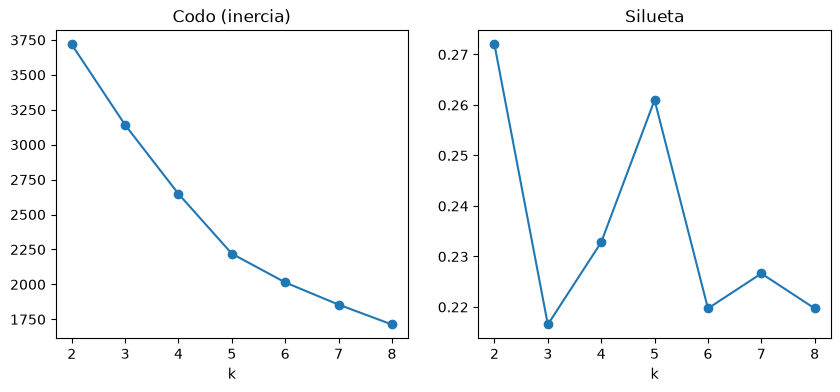

In [30]:
figura, (grafica_inercia, grafica_silueta) = plt.subplots(1, 2, figsize=(10, 4))

grafica_inercia.plot(list(inercia_por_k.keys()), list(inercia_por_k.values()), marker="o")
grafica_inercia.set_title("Codo (inercia)")
grafica_inercia.set_xlabel("k")

grafica_silueta.plot(list(silueta_por_k.keys()), list(silueta_por_k.values()), marker="o")
grafica_silueta.set_title("Silueta")
grafica_silueta.set_xlabel("k")

plt.show()

Hasta k=5 cada grupo nuevo aporta mucho. Después de k=5, la mejora cae a la mitad. Ese es el codo.

Silueta. El valor más alto es k=2 (0.272), pero k=5 (0.261) es el segundo y una diferencia de solo 0.011. Además, k=5 es un pico local: sube desde 0.233 en k=4 y baja a 0.220 en k=6. Los demás valores quedan entre 0.217 y 0.233.

Criterio de negocio. Dos segmentos son muy pocos para darle una acción distinta a cada uno, y cinco sí se pueden gestionar.

Con eso, tu justificación queda con tres patas: el codo está en 5, la silueta tiene un pico en 5 casi tan alto como el máximo, y 5 segmentos son manejables. En una celda Markdown di también por qué no elegiste k=2: “tiene la silueta más alta, pero separar a los vendedores en solo dos grupos no permite acciones distintas”.

## KMeans definitivo

In [31]:
cantidad_de_grupos_elegida = 5
modelo_kmeans_final = KMeans(n_clusters=cantidad_de_grupos_elegida, random_state=42, n_init=10)
vendedores["grupo"] = modelo_kmeans_final.fit_predict(datos_escalados)

display(vendedores["grupo"].value_counts().sort_index())

perfil_de_cada_grupo = vendedores.groupby("grupo")[columnas_de_vendedores].mean().round(2)
display(perfil_de_cada_grupo)

grupo
0    120
1    255
2     74
3    162
4    394
Name: count, dtype: int64

,pedidos_entregados,ventas_totales,flete_relativo,tasa_de_retraso,cantidad_de_categorias
grupo,,,,,
0,40.72,1567.77,0.52,0.07,2.38
1,173.91,24930.94,0.19,0.07,2.84
2,153.64,14459.38,0.24,0.09,10.54
3,26.94,4110.67,0.21,0.21,2.11
4,22.97,3395.81,0.18,0.05,2.37


In [32]:
medias_por_grupo = vendedores.groupby("grupo")[columnas_de_vendedores].mean()

nombre_grupos = {}
nombre_grupos[medias_por_grupo["pedidos_entregados"].idxmin() ] = "Vendedores con menos entregas"
nombre_grupos[medias_por_grupo["ventas_totales"].idxmax() ] = "Vendedores con más ventas"
nombre_grupos[medias_por_grupo["flete_relativo"].idxmax()] = "Vendedores con flete alto vs ventas"
nombre_grupos[medias_por_grupo["tasa_de_retraso"].idxmax()] = "Vendedores con problemas de entrega"
nombre_grupos[medias_por_grupo["cantidad_de_categorias"].idxmax()] = "Vendedores diversificados"

vendedores["nombre_grupo"] = vendedores["grupo"].map(nombre_grupos)
vendedores["nombre_grupo"].value_counts()

nombre_grupo
Vendedores con menos entregas          394
Vendedores con más ventas              255
Vendedores con problemas de entrega    162
Vendedores con flete alto vs ventas    120
Vendedores diversificados               74
Name: count, dtype: int64

## PCA A 2 COMPONENTES

PCA 1: 0.41061142 PCA2: 0.23425092 Total: 0.6448623457224648

In [33]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
comp = pca.fit_transform(datos_escalados)

vendedores["pc1"] = comp[:, 0]
vendedores["pc2"] = comp[:, 1]

print(pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum())

[0.41061142 0.23425092] 0.6448623457224648


In [34]:
vendedores.head()

,seller_id,pedidos_entregados,ventas_totales,flete_relativo,tasa_de_retraso,cantidad_de_categorias,grupo,nombre_grupo,pc1,pc2
0,001cca7ae9ae17fb1caed9dfb1094831,192,24116.13,0.353487,0.056277,2,1,Vendedores con más ventas,1.564370,0.706510
1,002100f778ceb8431b7a1020ff7ab48f,50,1216.60,0.639947,0.166667,1,0,Vendedores con flete alto vs ventas,-1.527552,1.489831
2,004c9cd9d87a3c30c522c48c4fc07416,156,19569.73,0.180089,0.077381,1,1,Vendedores con más ventas,1.491671,-0.412261
3,00720abe85ba0859807595bbf045a33b,10,709.30,0.322304,0.055556,1,4,Vendedores con menos entregas,-2.172297,0.227844
4,00ee68308b45bc5e2660cd833c3f81cc,130,19729.00,0.156370,0.072727,2,1,Vendedores con más ventas,1.565383,-0.396040


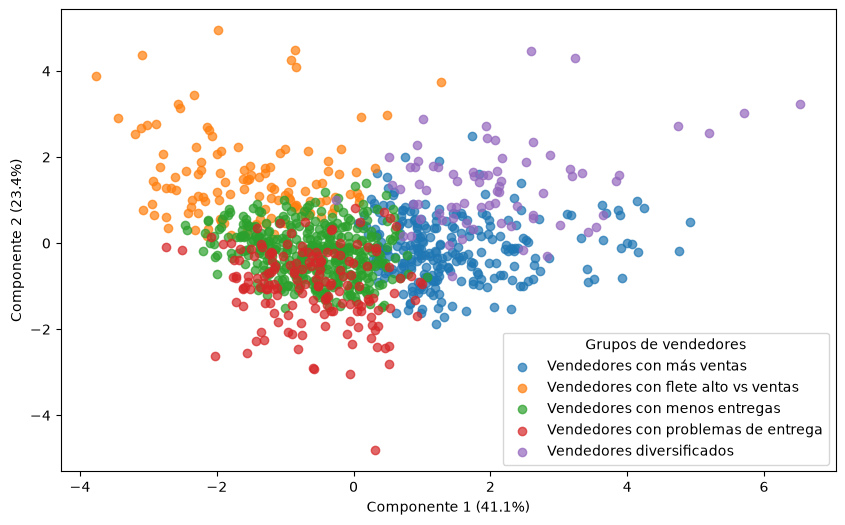

In [35]:
plt.figure(figsize=(10, 6))

for nombre_del_grupo in vendedores["nombre_grupo"].unique():
    vendedores_del_grupo = vendedores[vendedores["nombre_grupo"] == nombre_del_grupo]
    plt.scatter(
        vendedores_del_grupo["pc1"],
        vendedores_del_grupo["pc2"],
        label=nombre_del_grupo,
        alpha=0.7,
    )

porcentaje_pc1 = pca.explained_variance_ratio_[0] * 100
porcentaje_pc2 = pca.explained_variance_ratio_[1] * 100
plt.xlabel(f"Componente 1 ({porcentaje_pc1:.1f}%)")
plt.ylabel(f"Componente 2 ({porcentaje_pc2:.1f}%)")
plt.legend(title="Grupos de vendedores")
plt.show()

## ACCIONES CONCRETAS POR GRUPOS DE VENDEDORES

nombre_grupos[medias_por_grupo["pedidos_entregados"].idxmin() ] = "Vendedores con menos entregas"
nombre_grupos[medias_por_grupo["ventas_totales"].idxmax() ] = "Vendedores con más ventas"
nombre_grupos[medias_por_grupo["flete_relativo"].idxmax()] = "Vendedores con flete alto vs ventas"
nombre_grupos[medias_por_grupo["tasa_de_retraso"].idxmax()] = "Vendedores con problemas de entrega"
nombre_grupos[medias_por_grupo["cantidad_de_categorias"].idxmax()] = "Vendedores diversificados"

In [36]:
# 1. Definimos las variables mapeando los índices correctos de medias_por_grupo
grupo_con_menos_entregas = medias_por_grupo["pedidos_entregados"].idxmin()
grupo_con_mas_ventas = medias_por_grupo["ventas_totales"].idxmax()
grupo_con_flete_alto = medias_por_grupo["flete_relativo"].idxmax()
grupo_con_mas_retrasos = medias_por_grupo["tasa_de_retraso"].idxmax()
grupo_con_diversificados = medias_por_grupo["cantidad_de_categorias"].idxmax()

# 1. Construimos la tabla de segmentos con las 5 filas correspondientes
tabla_de_segmentos = pd.DataFrame([
    {
        "nombre": "Vendedores con problemas de entrega",
        "como_es": (
            f"Tasa de retraso de {medias_por_grupo.loc[grupo_con_mas_retrasos, 'tasa_de_retraso']:,.1%}, "
            f"frente a {vendedores['tasa_de_retraso'].mean():,.1%} del promedio"
        ), 
        "accion": "Alertar al vendedor cuando su retraso supere el umbral y revisar su proceso de despacho antes de sancionarlo",
    },
    {
        "nombre": "Vendedores con más ventas",
        "como_es": (
            f"Venden en promedio ${medias_por_grupo.loc[grupo_con_mas_ventas, 'ventas_totales']:,.0f}, "
            f"frente a ${vendedores['ventas_totales'].mean():,.0f} del promedio de todos los vendedores"
        ),
        "accion": "Alertar al vendedor cuando sus ventas sean menores a las del grupo con mas ventas y evaluar sus conocimientos y habilidades en ventas",
    },
    {
        "nombre": "Vendedores con menos entregas", 
        "como_es": (
            f"Pocas entregas con un promedio de {medias_por_grupo.loc[grupo_con_menos_entregas, 'pedidos_entregados']:,.1f} pedidos, "
            f"frente a {vendedores['pedidos_entregados'].mean():,.1f} del promedio general"
        ), 
        "accion": "Ofrecer capacitaciones logísticas o incentivos de volumen para ayudarles a incrementar su cantidad de despachos.",
    },
    {
        "nombre": "Vendedores con flete alto vs ventas", 
        "como_es": (
            f"Flete relativo de {medias_por_grupo.loc[grupo_con_flete_alto, 'flete_relativo']:,.1%}, "
            f"frente a {vendedores['flete_relativo'].mean():,.1%} del promedio general"
        ), 
        "accion": "Sugerir optimización de empaques, contratos con transportadoras aliadas o revisión de tarifas geográficas para reducir costos de envío.",
    },
    {
        "nombre": "Vendedores con diversificados", 
        "como_es": (
            f"Operan en promedio en {medias_por_grupo.loc[grupo_con_diversificados, 'cantidad_de_categorias']:,.1f} categorías, "
            f"frente a {vendedores['cantidad_de_categorias'].mean():,.1f} del promedio general"
        ), 
        "accion": "Incluirlos en campañas promocionales cruzadas (cross-selling) y darles herramientas avanzadas de gestión multi-categoría.",
    },
])

display(tabla_de_segmentos)

,nombre,como_es,accion
0,Vendedores con problemas de entrega,"Tasa de retraso de 21.2%, frente a 8.6% del pr...",Alertar al vendedor cuando su retraso supere e...
1,Vendedores con más ventas,"Venden en promedio $24,931, frente a $9,572 de...",Alertar al vendedor cuando sus ventas sean men...
2,Vendedores con menos entregas,Pocas entregas con un promedio de 23.0 pedidos...,Ofrecer capacitaciones logísticas o incentivos...
3,Vendedores con flete alto vs ventas,"Flete relativo de 52.5%, frente a 23.3% del pr...","Sugerir optimización de empaques, contratos co..."
4,Vendedores con diversificados,"Operan en promedio en 10.5 categorías, frente ...",Incluirlos en campañas promocionales cruzadas ...


## GUARDANDO ARCHIVOS CSV

In [37]:
vendedores.to_csv("app/data/vendedores_segmentados.csv", index=False)
tabla_de_segmentos.to_csv("app/data/segmentos_de_vendedores.csv", index=False)
print(tabla_de_segmentos.shape, vendedores.shape)

(5, 3) (1005, 10)


### Opción elegida: 3B · Segmentación de vendedores

**Por qué la 3B y no la 3A**
- El modelo a utilizar es algo que ya habia usado en la tarea anterior y se me hacia más fácil tenerlo de ejemplo.
- Sobre los datos a utilizar estime que era mejor comprender la forma de los grupos de vendedores para poder tomar acciones que permitan que mejoren sus resultados
- La segmentación de vendedores según sus resultados le permite a Olist tomar decisiones y crear planes de acción según cada grupo y asi mejorarlos en cuanto a estrategias de ventas.
- En la 3A parte de la nota se mide contra los pedidos reales de junio, que no se pueden ver. La 3B se evalúa solo con lo que se entrega y se puede verificar en el notebook.


**Decisiones**
- Vendedores incluidos: al menos 10 pedidos entregados, porque con menos pedidos una tasa como la de retraso cambia mucho por un solo pedido y no describe bien al vendedor. Quedaron 1,005 vendedores.
- Variables: `pedidos_entregados` (volumen de pedidos), `ventas_totales` (suma de precios), `flete_relativo` (flete sobre ventas), `tasa_de_retraso` (fracción de artículos que llegó después de la fecha prometida) y `cantidad_de_categorias` (variedad de lo que vende).
- Logaritmo en `pedidos_entregados` y `ventas_totales`, porque tienen cola larga. En `ventas_totales` la media (9,571) es unas 2.5 veces la mediana (3,850) y el máximo (192,353) es unas 50 veces la mediana. En `pedidos_entregados` la media es 2.37 veces su mediana. Las otras tres no se transformaron porque su media está cerca de su mediana (1.16, 1.23 y 1.52 veces).
- Retraso: se cuenta por artículo y no por pedido, así que los pedidos con varios artículos pesan más.
- k = 5: la inercia baja de 2,648 (k=4) a 2,220 (k=5), una caída de 428, y de k=5 a k=6 solo baja 206 (a 2,014). Ese es el codo. La silueta tiene un pico local en k=5 (0.261), casi igual al máximo de k=2 (0.272). No elegí k=2 porque con solo dos grupos no se pueden definir acciones distintas, y cinco segmentos sí se pueden gestionar.

**Límites**
- Las siluetas son bajas (0.22 a 0.27): los vendedores forman más un continuo que grupos nítidos, así que los segmentos se traslapan en los bordes.
- El retraso se mide por artículo, lo que da más peso a los pedidos grandes.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [38]:
consulta_comentarios = """
SELECT order_id, review_score, review_comment_message
FROM final.order_reviews
WHERE review_comment_message IS NOT NULL
  AND TRIM(review_comment_message) <> ''
"""
comentarios = pd.read_sql(consulta_comentarios, motor)
print(comentarios.shape)

muestra_de_comentarios = comentarios.sample(n=1000, random_state=42).reset_index(drop=True)
print(muestra_de_comentarios.shape)
display(muestra_de_comentarios.head())

(33592, 3)
(1000, 3)


,order_id,review_score,review_comment_message
0,1f21b692c9d8f0368278413ecd0878f3,4,Blz
1,ec4015e0b9b735844b7b6c8066835378,5,Chegou bem antes do prazo e Happy ficou lindo ...
2,9a63315dcf91f9309c3a2307abbcb9b8,5,"Chegou super rápido até antes do prazo, obrigada."
3,4c761041674866c683398d2c3d0d9163,4,Achei só muito demorado o prazo para a entrega.
4,3c7a723fc09b996f715cfddba2377163,5,"Produto chegou em uma semana, embalagem bem pr..."


In [39]:
!pip install -q transformers


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## CODIGO QUE SIRVIO PARA DETERMINAR SI PODIA HACERSE LOCALMENTE

In [40]:
import time, torch
from transformers import pipeline

clasificador = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=0 if torch.cuda.is_available() else -1,
)

textos = muestra_de_comentarios["review_comment_message"].str.strip().tolist()

t0 = time.time()
prueba = clasificador(textos[:30], batch_size=16, truncation=True, max_length=256)
seg = time.time() - t0
print(prueba[:3])
print(f"{seg:.1f} s para 30 -> estimado para {len(textos)}: {seg / 30 * len(textos) / 60:.1f} min")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 27828.19it/s]


[{'label': 'neutral', 'score': 0.4580898880958557}, {'label': 'positive', 'score': 0.8444769978523254}, {'label': 'positive', 'score': 0.8903636932373047}]
1.6 s para 30 -> estimado para 1000: 0.9 min


In [41]:
import torch
from transformers import pipeline

clasificador = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=0 if torch.cuda.is_available() else -1,   # GPU si está activa
)

textos = muestra_de_comentarios["review_comment_message"].str.strip().tolist()
salidas = clasificador(textos, batch_size=32, truncation=True, max_length=256)

muestra_de_comentarios["label_modelo"] = [resultados["label"] for resultados in salidas]
muestra_de_comentarios["confianza"] = [resultados["score"] for resultados in salidas]
muestra_de_comentarios["label_modelo"].value_counts()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 28707.57it/s]


label_modelo
positive    539
negative    236
neutral     225
Name: count, dtype: int64

## GUARDADO RESULTADOS DE SENTIMIENTOS EN CSV

In [42]:
import os
RUTA_CACHE = "app/data/sentimiento_comentarios_cache.csv"

if os.path.exists(RUTA_CACHE):
    muestra_de_comentarios = pd.read_csv(RUTA_CACHE)
else:
    salidas = clasificador(textos, batch_size=16, truncation=True, max_length=256)
    muestra_de_comentarios["label_modelo"] = [resultados["label"] for resultados in salidas]
    muestra_de_comentarios["confianza"] = [resultados["score"] for resultados in salidas]
    muestra_de_comentarios.to_csv(RUTA_CACHE, index=False)

muestra_de_comentarios["label_modelo"].value_counts()

label_modelo
positive    539
negative    236
neutral     225
Name: count, dtype: int64

In [43]:
# TU CÓDIGO AQUÍ
mapa_modelo = {"negative": "negativo", "neutral": "neutro", "positive": "positivo",
               "LABEL_0": "negativo", "LABEL_1": "neutro", "LABEL_2": "positivo"}
muestra_de_comentarios["sentimiento"] = muestra_de_comentarios["label_modelo"].map(mapa_modelo)
muestra_de_comentarios["estrellas_grupo"] = muestra_de_comentarios["review_score"].map(
    {1: "negativo", 2: "negativo", 3: "neutro", 4: "positivo", 5: "positivo"})

orden = ["negativo", "neutro", "positivo"]
cruzada = pd.crosstab(muestra_de_comentarios["estrellas_grupo"], muestra_de_comentarios["sentimiento"]).reindex(index=orden, columns=orden)
display(cruzada)
display((pd.crosstab(muestra_de_comentarios["estrellas_grupo"], muestra_de_comentarios["sentimiento"], normalize="index")
         .reindex(index=orden, columns=orden) * 100).round(1))

coincidencia = (muestra_de_comentarios["estrellas_grupo"] == muestra_de_comentarios["sentimiento"]).mean()
print(f"Coincidencia: {coincidencia:.1%}")

sentimiento,negativo,neutro,positivo
estrellas_grupo,,,
negativo,154,88,2
neutro,33,29,15
positivo,49,108,522


sentimiento,negativo,neutro,positivo
estrellas_grupo,,,
negativo,63.1,36.1,0.8
neutro,42.9,37.7,19.5
positivo,7.2,15.9,76.9


Coincidencia: 70.5%


In [44]:
desacuerdos = muestra_de_comentarios[muestra_de_comentarios["estrellas_grupo"] != muestra_de_comentarios["sentimiento"]]
pd.set_option("display.max_colwidth", 300)
desacuerdos.sample(12, random_state=42)[["review_score", "sentimiento", "confianza", "review_comment_message"]]

,review_score,sentimiento,confianza,review_comment_message
911,1,neutro,0.703898,"Até hoje, 17/05/2018 ainda não recebi o produto, não consta nem a chegada a minha cidade. O pedido foi feito em 02/04/2018"
566,1,neutro,0.582315,"O jogo de bolas de bilhar que comprei é totalmente diferente do que foi entregue, sendo diferente, a cor, material e diâmetro da bola. Quanto ao recebimento do dinheiro de volta? Como devo proceder?"
305,4,negativo,0.893672,"Capinha e muito boa, mas a película e horrível."
298,1,neutro,0.487849,"No status do meu pedido estava ""dificuldade na entrega"" entrei em contato e disseram que em 48 hs iriam retornar, só que o retorno aconteceu uma semana depois e sem novo prazo para entrega."
882,3,negativo,0.686272,Acho que a loja não deveria mais trabalhar com os correios
51,1,neutro,0.534987,Produto não entregue
130,4,neutro,0.629462,"A caixa do jogo veio com um pequeno rasgado, mas eu não quis trocar. No mais, tudo ocorreu muito bem."
931,1,neutro,0.588996,"Estou aguardando a encomenda. \r\nRecebi o aviso de dificuldade na entrega, mas ninguém entrou em contato para dizer o q realmente aconteceu."
937,1,neutro,0.493203,Preciso resolver um.problema comprei dois produtos mais recebi apenas um
343,5,neutro,0.821090,Entrega rápida produtos bem acondicionado embalagem lacrada e com todos os itens em perfeito estado


In [45]:
import re
neg = muestra_de_comentarios[muestra_de_comentarios["sentimiento"] == "negativo"]["review_comment_message"].str.lower()
temas = {"entrega/retraso": r"atras|prazo|demor|não chegou|nao chegou|entrega",
         "producto defectuoso/dañado": r"defeito|quebr|danific|estrag",
         "producto distinto/incompleto": r"diferente|errado|faltou|incomplet"}
for tema, patron in temas.items():
    print(f"{tema}: {neg.str.contains(patron).mean():.1%} de los comentarios negativos")

entrega/retraso: 28.8% de los comentarios negativos
producto defectuoso/dañado: 2.1% de los comentarios negativos
producto distinto/incompleto: 8.1% de los comentarios negativos


### Preguntas

1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?
    - El sentimiento del modelo coincide con el de las estrellas en un '70.5%' de los 12 comentarios de la muestra, es decir, en unos 7 de cada 10. El otro 29.5% son desacuerdos.
    La mayor confusión está en los comentarios que el cliente escribió con tono neutral pero que expresan un problema. Por ejemplo, "producto no entregado" o "pedí dos y solo llegó uno" no tienen palabras de enojo, y el modelo los clasificó como 'neutral' aunque las estrellas fueran 1 o 2 (negativo). En la tabla cruzada, esa es la celda de "negativo por estrellas, neutral para el modelo".
    También hay un error en el sentido contrario: comentarios con 4 estrellas que el modelo marcó como 'negativo' porque su parte final habla de algo malo (1 casos), aunque la calificación del cliente fue positiva.
    

2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?
    -Una posible razón es que el modelo detecta el 'tono emocional' del texto, y una queja escrita de forma objetiva se lee como neutral. Las estrellas sí reflejan que el cliente quedó molesto.
    1. 305	4	negativo	0.893672	Capinha e muito boa, mas a película e horrível.  -> El modelo se equivoca al clasificar como negativo este comentario que es neutro, más teniendo en cuenta las 4 estrellas
    2. 911	1	neutro	0.703898	Até hoje, 17/05/2018 ainda não recebi o produto, não consta nem a chegada a minha cidade. O pedido foi feito em 02/04/2018  -> El modelo se equivoca al clasificar como neutro un comentario negativo quede explica no saber nada de su paquete desde hace mucho tiempo, y solo tiene 1 estrella.
    3. 51	1	neutro	0.534987	Produto não entregue -> Se equivoca el modelo al decir que es neutro con apenas una estrella, y la negativa de producto no entregado.
    4. 937	1	neutro	0.493203	Preciso resolver um.problema comprei dois produtos mais recebi apenas um -> Falla el modelo al decir que es nuetro cuando solo tiene un estrella y el comentario refleja un problema de paquete incompleto.
    5. 735	5	neutro	0.531485	bem rapido -> Falla el modelo al decir que esto es neutro cuando deberia ser positivo porque expresa algo bueno y tine 5 estrellas.
    
3. ¿Qué dice el texto que las estrellas no dicen?
    - El texto da la explicación de la situación , el porque de las estrellas en su evaluación.
    - El texto sirve para mostrar discrepancias o una vehemencia mayor que a un simple número, como un caso estrellas 3, sentimiento neutro pero el cliente dice que al tienda mejor ni trabajara con envios.

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

In [53]:
# TU CÓDIGO AQUÍ
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

# Mismas variables que los otros modelos: crear_variables + preparar_columnas
preparador = Pipeline([
    ("crear_variables", FunctionTransformer(crear_variables, validate=False)),
    ("preparar_columnas", clone(preparar_columnas)),
])
X_ent = preparador.fit_transform(pedidos_de_entrenamiento[columnas_de_entrada])   # fit SOLO con train
X_val = preparador.transform(pedidos_de_validacion[columnas_de_entrada])
if hasattr(X_ent, "toarray"):                       # el one-hot puede devolver matriz dispersa
    X_ent, X_val = X_ent.toarray(), X_val.toarray()
X_ent, X_val = X_ent.astype("float32"), X_val.astype("float32")
y_ent = pedidos_de_entrenamiento["mala_resena"].values.astype("float32")

# Validación interna: el 10 % más reciente del train (para parar el entrenamiento a tiempo)
corte_interno = pedidos_de_entrenamiento["order_purchase_timestamp"].quantile(.9)
es_interna = (pedidos_de_entrenamiento["order_purchase_timestamp"] >= corte_interno).values
X_tr, X_es = X_ent[~es_interna], X_ent[es_interna]
y_tr, y_es = y_ent[~es_interna], y_ent[es_interna]

print("Entradas:", X_tr.shape[1], "| train:", len(X_tr), "| interna:", len(X_es), "| validación:", len(X_val))

Entradas: 144 | train: 55658 | interna: 6185 | validación: 15461


In [54]:
class RedRiesgo(nn.Module):
    def __init__(self, n_entradas, ocultas=(64, 32), dropout=0.3):
        super().__init__()
        capas, previo = [], n_entradas
        for h in ocultas:
            capas += [nn.Linear(previo, h), nn.ReLU(), nn.Dropout(dropout)]
            previo = h
        capas.append(nn.Linear(previo, 1))          # una salida: logit de "mala reseña"
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x).squeeze(1)


def entrenar_red(X_tr, y_tr, X_es, y_es, ocultas=(64, 32), dropout=0.3, lr=1e-3,
                 epocas=60, paciencia=8, tamano_lote=512, semilla=SEMILLA):
    torch.manual_seed(semilla)
    red = RedRiesgo(X_tr.shape[1], ocultas, dropout)
    perdida = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.Adam(red.parameters(), lr=lr, weight_decay=1e-4)
    cargador = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
                          batch_size=tamano_lote, shuffle=True)
    X_es_t, y_es_t = torch.from_numpy(X_es), torch.from_numpy(y_es)

    historial = {"entrenamiento": [], "validacion_interna": []}
    mejor, mejor_estado, sin_mejora = np.inf, None, 0
    for epoca in range(epocas):
        red.train()
        acumulado = 0.0
        for xb, yb in cargador:
            optimizador.zero_grad()
            l = perdida(red(xb), yb)
            l.backward()
            optimizador.step()
            acumulado += l.item() * len(xb)
        red.eval()
        with torch.no_grad():
            l_val = perdida(red(X_es_t), y_es_t).item()
        historial["entrenamiento"].append(acumulado / len(X_tr))
        historial["validacion_interna"].append(l_val)

        if l_val < mejor - 1e-4:                       # guarda la mejor época
            mejor, mejor_estado, sin_mejora = l_val, copy.deepcopy(red.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:                # parada temprana
                break
    red.load_state_dict(mejor_estado)
    return red, historial


def predecir(red, X):
    red.eval()
    with torch.no_grad():
        return torch.sigmoid(red(torch.from_numpy(X))).numpy()


red, historial = entrenar_red(X_tr, y_tr, X_es, y_es)
probabilidades_red = predecir(red, X_val)
precision_red = precision_en_el_10_por_ciento(etiquetas_de_validacion, probabilidades_red)
print(f"Épocas usadas: {len(historial['entrenamiento'])} | precisión en el 10 %: {float(precision_red):.3f}")

Épocas usadas: 25 | precisión en el 10 %: 0.482


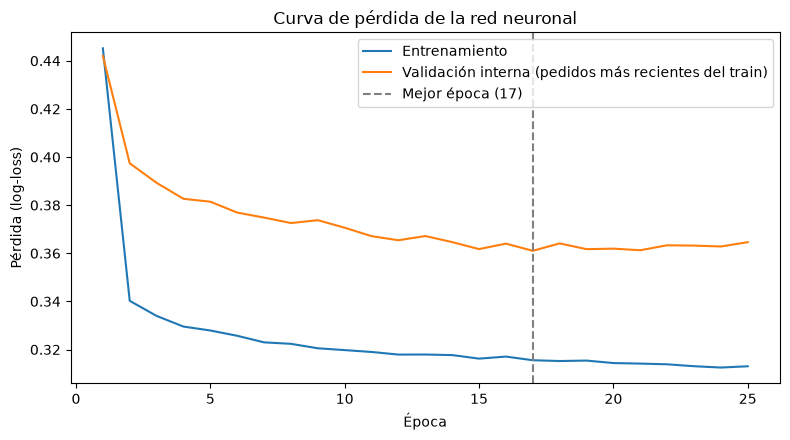

In [55]:
mejor_epoca = int(np.argmin(historial["validacion_interna"]))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(historial["entrenamiento"]) + 1), historial["entrenamiento"], label="Entrenamiento")
ax.plot(range(1, len(historial["validacion_interna"]) + 1), historial["validacion_interna"],
        label="Validación interna (pedidos más recientes del train)")
ax.axvline(mejor_epoca + 1, ls="--", color="gray", label=f"Mejor época ({mejor_epoca + 1})")
ax.set_xlabel("Época"); ax.set_ylabel("Pérdida (log-loss)")
ax.set_title("Curva de pérdida de la red neuronal")
ax.legend()
plt.tight_layout(); plt.show()

In [56]:
comparacion = pd.DataFrame({
    "metodo": ["Azar", "Regla del retraso", "Regresión logística", "XGBoost", "Red neuronal"],
    "precision_en_el_10": [precision_del_azar, precision_de_la_regla, precision_regresion,
                           precision_xgboost, precision_red],
    "auc_roc": [None, None,
                roc_auc_score(etiquetas_de_validacion, probabilidades_regresion),
                roc_auc_score(etiquetas_de_validacion, probabilidades_xgboost),
                roc_auc_score(etiquetas_de_validacion, probabilidades_red)],
})
comparacion["veces_el_azar"] = comparacion["precision_en_el_10"] / precision_del_azar
comparacion.round(3)

,metodo,precision_en_el_10,auc_roc,veces_el_azar
0,Azar,0.119,NaN,1.000
1,Regla del retraso,0.384,NaN,3.230
2,Regresión logística,0.460,0.716,3.866
3,XGBoost,0.485,0.740,4.079
4,Red neuronal,0.482,0.747,4.051


In [57]:
precisiones = []
for s in range(5):
    r, _ = entrenar_red(X_tr, y_tr, X_es, y_es, semilla=s)
    precisiones.append(float(precision_en_el_10_por_ciento(etiquetas_de_validacion, predecir(r, X_val))))
print(np.round(precisiones, 3), f"| media {np.mean(precisiones):.3f} ± {np.std(precisiones):.3f}")

[0.483 0.479 0.483 0.479 0.483] | media 0.481 ± 0.002


## Parte 5 · Despliegue

- URL de la API en Render: **[pegar aquí]**
- URL de la app de Streamlit: **[pegar aquí]**

Versiones de este entorno (para su `requirements.txt` de la API):

In [47]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==3.1.0
numpy==2.5.4
scikit-learn==1.9.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):

In [48]:
import requests
URL_API = "https://SU-API.onrender.com"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'detail': 'Not Found'}

## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, solo el enlace o una copia.

## Uso de IA

Indiquen qué herramientas de IA usaron y para qué. Todo lo que entregan lo deben poder explicar en la defensa.

In [ ]:
fastapi=={fastapi.__version__}\nuvicorn=={uvicorn.__version__}\npydantic=={pydantic.__version__}')

NameError: name 'panda' is not defined